# **Lab 8 Task - Edge Detection**

**Objective:** Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Butterfly.jpg'

## **Task 1: Apply Edge Detection Methods**

Selected image: `Butterfly.jpg`

In [2]:
img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

### **Sobel Edge Detector**

In [3]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

### **Prewitt Edge Detector**

In [4]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

### **Canny Edge Detector**

In [5]:
canny_edges = cv2.Canny(blurred, 50, 150)

### **Results**

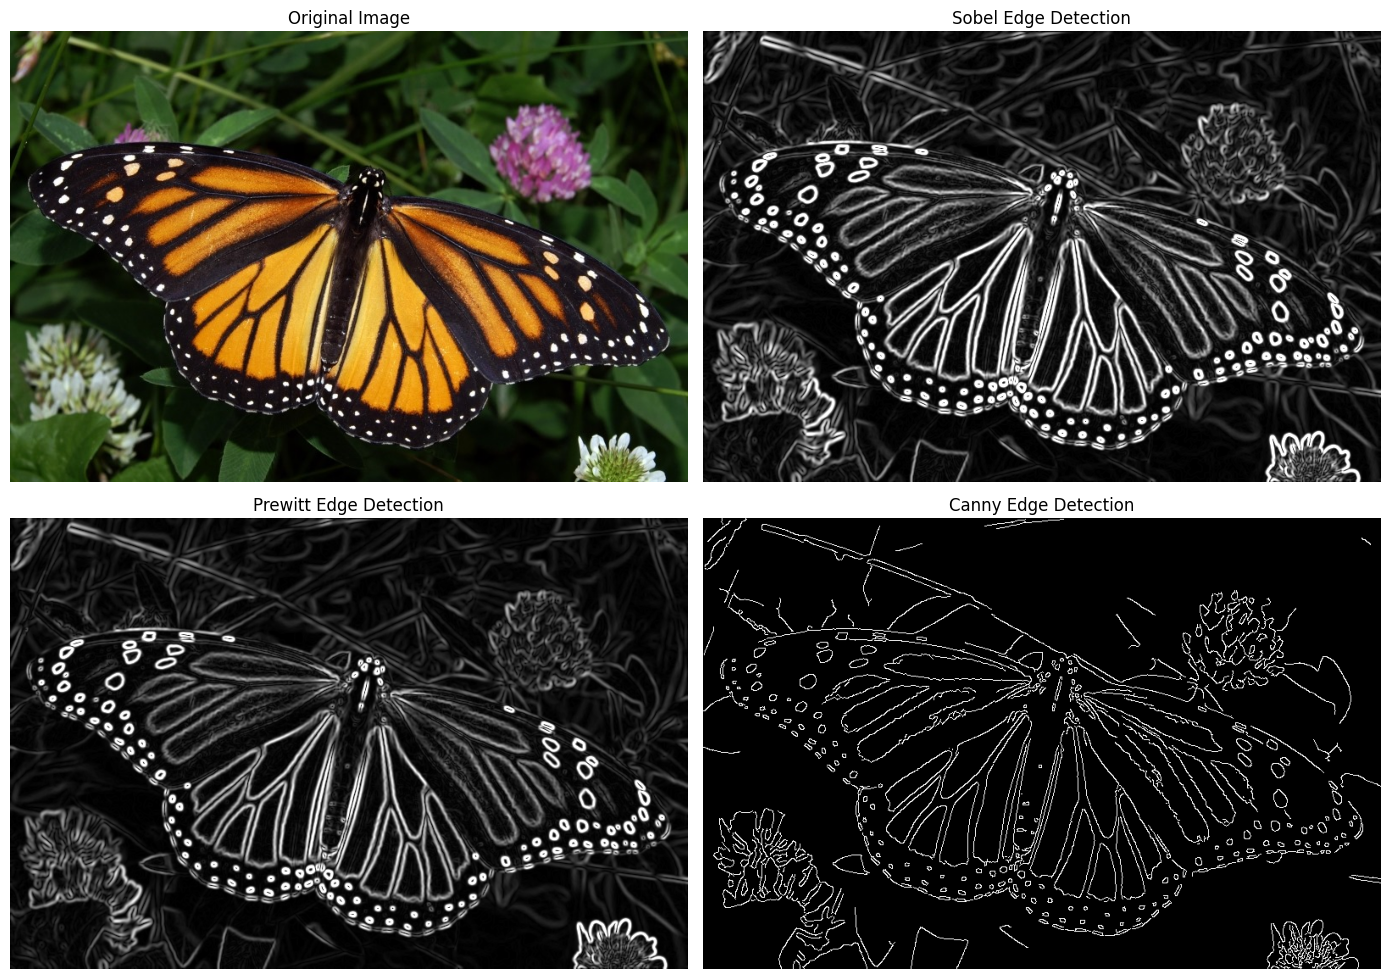

In [6]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

**Comparison:**
- **Sobel** gives thick, gradient-based edges with varying intensity. Its built-in smoothing (center weight of 2) makes it fairly resistant to noise, and the wing veins and black borders stand out clearly.
- **Prewitt** looks very similar to Sobel but slightly weaker and a little noisier, because its kernel gives equal weight to all rows/columns and has no extra smoothing.
- **Canny** produces thin, binary, one-pixel-wide edges thanks to non-maximum suppression and hysteresis thresholding. It gives the cleanest, best-localized outlines of the wings, veins and white spots, while ignoring most of the weak texture in the background leaves.

## **Task 2: Investigate the Effect of Canny Thresholds**

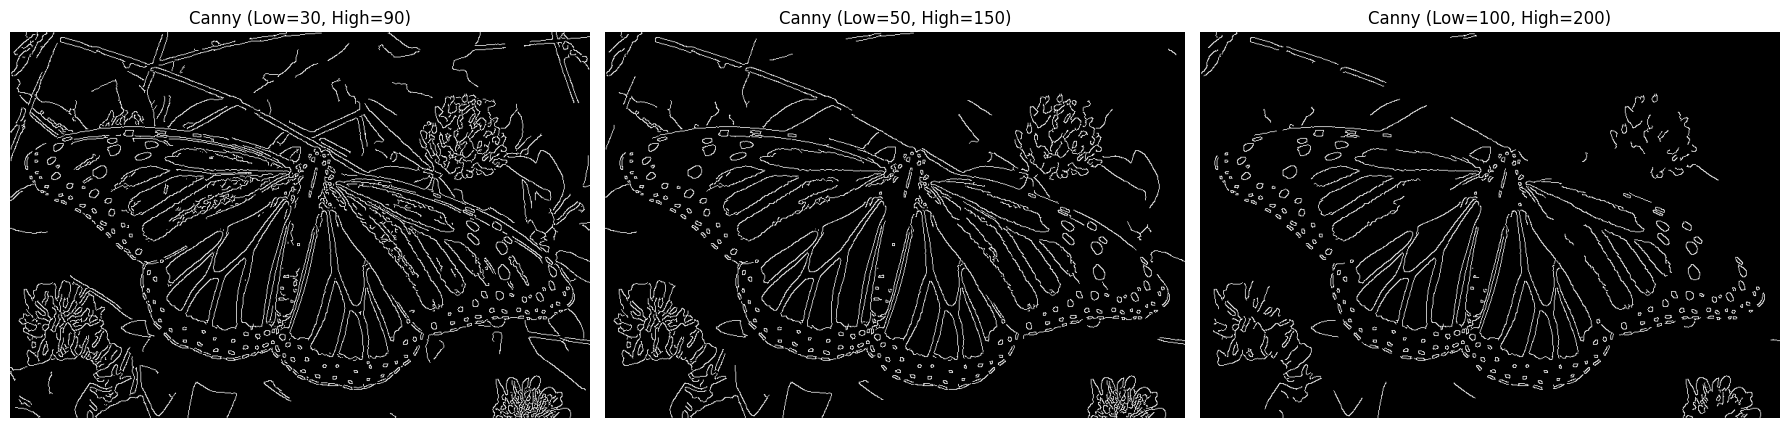

In [7]:
thresholds = [(30, 90), (50, 150), (100, 200)]
canny_results = [cv2.Canny(blurred, low, high) for low, high in thresholds]

plt.figure(figsize=(18, 6))
for i, ((low, high), edges) in enumerate(zip(thresholds, canny_results)):
    plt.subplot(1, 3, i + 1), plt.imshow(edges, cmap='gray'), plt.title(f'Canny (Low={low}, High={high})'), plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
for (low, high), edges in zip(thresholds, canny_results):
    print(f'Low={low}, High={high} -> Edge pixels: {np.count_nonzero(edges)}')

Low=30, High=90 -> Edge pixels: 33792
Low=50, High=150 -> Edge pixels: 23434
Low=100, High=200 -> Edge pixels: 16823


### **Explanation**

Canny uses two thresholds for hysteresis: pixels with gradient magnitude above **High** are accepted as strong edges, pixels below **Low** are rejected, and pixels in between are kept only if they are connected to a strong edge.

- **Low = 30, High = 90:** The thresholds are low, so many weak gradients pass. This detects the **largest number of edges**, showing fine details such as the small white spots, thin wing veins and lots of texture in the leaves and flowers in the background. However, it also picks up more noise and unimportant background clutter.
- **Low = 50, High = 150:** A balanced setting. The main structures of the butterfly (wing outlines, veins, spots) remain clear, while much of the background texture and noise is removed. The number of edges is moderate.
- **Low = 100, High = 200:** The thresholds are high, so only strong, high-contrast edges survive. This gives the **fewest edges**, mostly the outer wing borders and the strongest veins. The image looks clean, but fine details are lost and some edges become broken or incomplete.

**Conclusion:** Increasing the thresholds decreases the number of detected edges and reduces noise, but also reduces the visibility of fine image details. Decreasing the thresholds reveals more detail but adds noise and false edges. A medium pair (such as 50/150, a 1:3 ratio) usually gives the best trade-off.